# preprocessing for Healthcare

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("healthcare-dataset-stroke-data.csv")
df.head()


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


# the target is the Stroke and the other columns are features

###
Column Name          | Data Type            | Description
---------------------|----------------------|----------------------------------------------------------------------------------
id                   | Integer / Identifier | Unique identification number assigned to each patient.
gender               | Categorical          | The gender of the patient (Male, Female, or Other).
age                  | Numeric (Float)      | The age of the patient in years.
hypertension         | Binary (0 / 1)       | 0 = Patient does not have hypertension, 1 = Patient has hypertension.
heart_disease        | Binary (0 / 1)       | 0 = Patient does not have pre-existing heart disease, 1 = Patient has heart disease.
ever_married         | Categorical          | Indicates whether the patient has ever been married (Yes or No).
work_type            | Categorical          | The occupation type (Private, Self-employed, Govt_job, children, or Never_worked).
Residence_type       | Categorical          | The type of area where the patient lives (Urban or Rural).
avg_glucose_level    | Numeric (Float)      | The average blood glucose level of the patient (measured in mg/dL).
bmi                  | Numeric (Float)      | Body Mass Index of the patient (some values may be missing / NaN).
smoking_status       | Categorical          | Smoking history (formerly smoked, never smoked, smokes, or Unknown).
stroke               | Binary (Target)      | Target variable: 0 = Patient did not have a stroke, 1 = Patient had a stroke.

In [3]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [4]:
df.info()
# 5 str
# 4 int
# 3 float

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 634.7 KB


In [5]:
df.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='str')

In [6]:
df.isnull().sum().sort_values(ascending=False) # the bmi has a null values

bmi                  201
id                     0
age                    0
gender                 0
hypertension           0
heart_disease          0
work_type              0
ever_married           0
Residence_type         0
avg_glucose_level      0
smoking_status         0
stroke                 0
dtype: int64

In [7]:
df.duplicated().sum() # there's no duplicated rows

np.int64(0)

# Data cleaning

In [8]:
df.drop(['id'],axis=1,inplace=True)


In [9]:
df.reset_index(drop=True,inplace=True)

<Axes: ylabel='Frequency'>

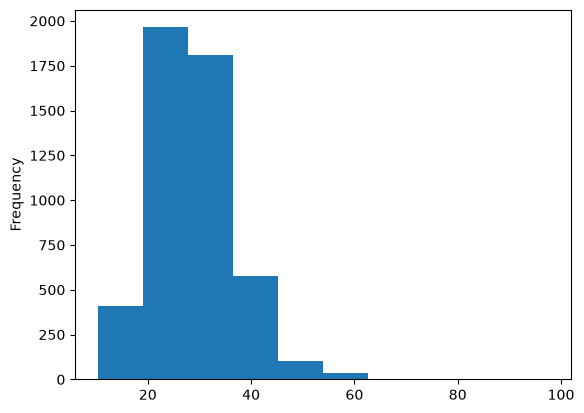

In [10]:
# a histogram for bmi

df['bmi'].plot(kind='hist')

In [11]:
df['bmi'].skew()
# it's an outlier because it;s bigger than 0.5, so we will fill it with the median(don't affected by the outliers)

np.float64(1.0553402052962912)

In [12]:
from sklearn.impute import SimpleImputer
imputer=SimpleImputer(missing_values=np.nan, strategy='median')
df[['bmi']]=imputer.fit_transform(df[['bmi']])

In [13]:
df.isnull().sum().sort_values(ascending=False) # no null values here

gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

<Axes: xlabel='bmi', ylabel='stroke'>

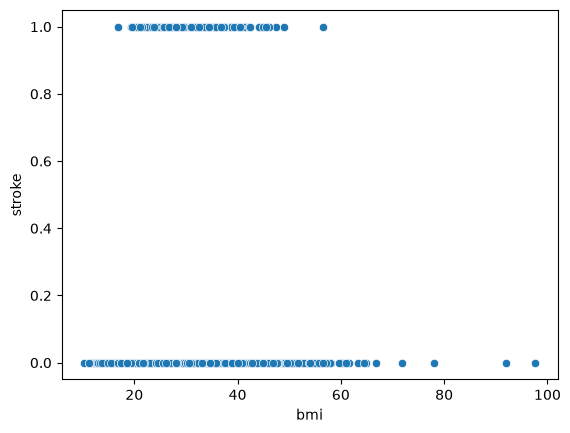

In [14]:
#  visualization

sns.scatterplot(data=df,x='bmi',y='stroke')

<Axes: xlabel='avg_glucose_level', ylabel='stroke'>

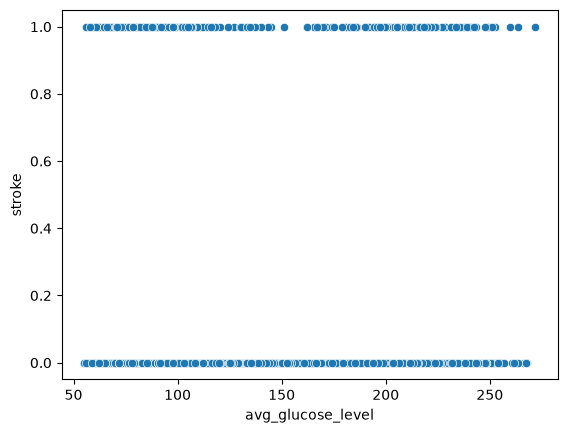

In [15]:
plt.Figure(figsize=(50,10))
sns.scatterplot(data=df,x='avg_glucose_level',y='stroke',)

<Axes: xlabel='age', ylabel='stroke'>

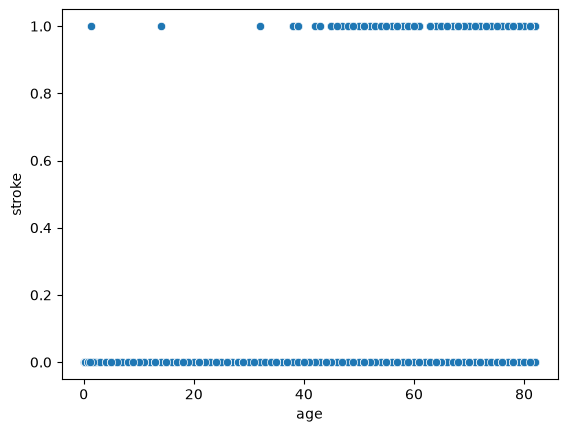

In [16]:

sns.scatterplot(data=df,x='age',y='stroke')

<Axes: xlabel='gender', ylabel='stroke'>

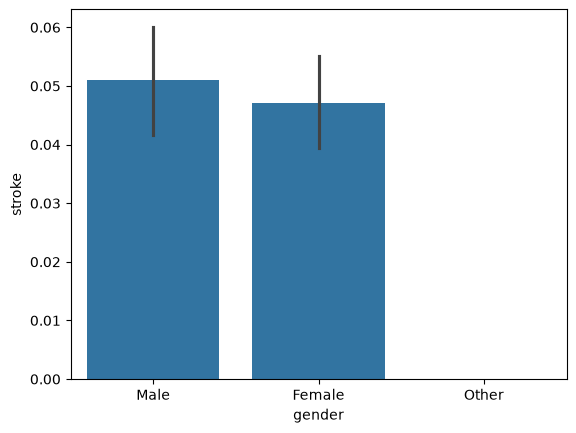

In [17]:
sns.barplot(data=df,x='gender',y='stroke')

<Axes: xlabel='ever_married', ylabel='stroke'>

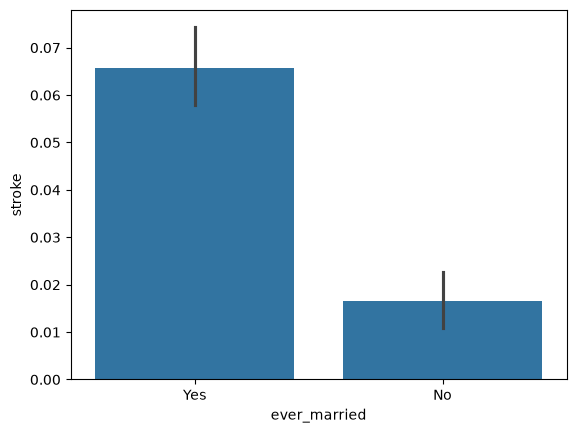

In [18]:
sns.barplot(data=df,x='ever_married',y='stroke')

In [19]:
for col in df.select_dtypes('object').columns:
    print(f"{col} number unique: ",df[col].nunique())
    print("-"*50)

gender number unique:  3
--------------------------------------------------
ever_married number unique:  2
--------------------------------------------------
work_type number unique:  5
--------------------------------------------------
Residence_type number unique:  2
--------------------------------------------------
smoking_status number unique:  4
--------------------------------------------------


C:\Users\abdoa\AppData\Local\Temp\ipykernel_22348\3796915109.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes('object').columns:


In [20]:
for col in df.select_dtypes('number').columns:
    print(f"{col} number unique: ",df[col].nunique())
    print("-"*50)

age number unique:  104
--------------------------------------------------
hypertension number unique:  2
--------------------------------------------------
heart_disease number unique:  2
--------------------------------------------------
avg_glucose_level number unique:  3979
--------------------------------------------------
bmi number unique:  418
--------------------------------------------------
stroke number unique:  2
--------------------------------------------------


In [21]:
from sklearn.preprocessing import OneHotEncoder
ohe=OneHotEncoder(sparse_output=False,
                      drop='first',
                      handle_unknown='ignore'
).set_output(transform='pandas')

In [22]:
temp = ohe.fit_transform(df[['gender']])

In [23]:
df = pd.concat([df,temp],axis=1)

In [24]:
em = ohe.fit_transform(df[['ever_married']])

In [25]:
df = pd.concat([df,em],axis=1)

In [26]:
rt = ohe.fit_transform(df[['Residence_type']])

In [27]:
df = pd.concat([df,rt],axis=1)

In [28]:
WT = ohe.fit_transform(df[['work_type']])

In [29]:
df = pd.concat([df,WT],axis=1)

In [30]:
ST = ohe.fit_transform(df[['smoking_status']])

In [31]:
df = pd.concat([df,ST],axis=1)

In [32]:
df.drop(['gender','Residence_type','ever_married','work_type','smoking_status'],axis=1,inplace=True)

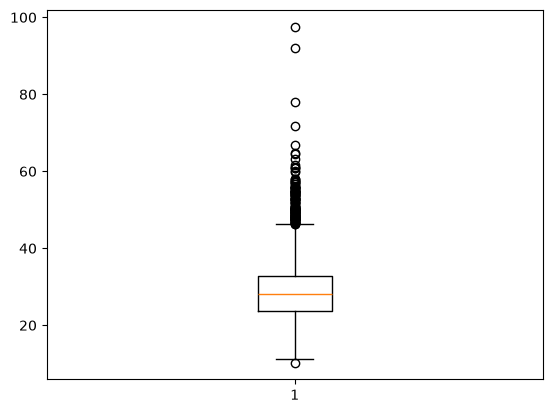

In [33]:
plt.boxplot(df['bmi'])
plt.show()

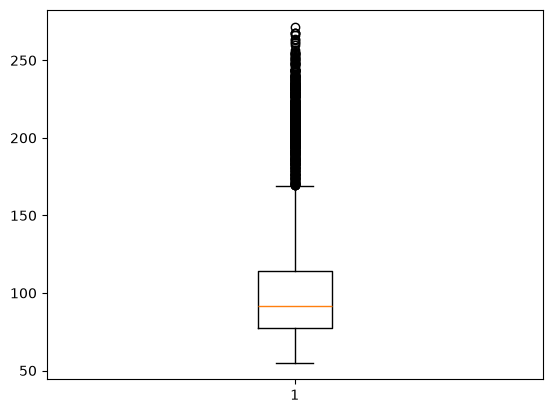

In [34]:
plt.boxplot(df['avg_glucose_level'])
plt.show()

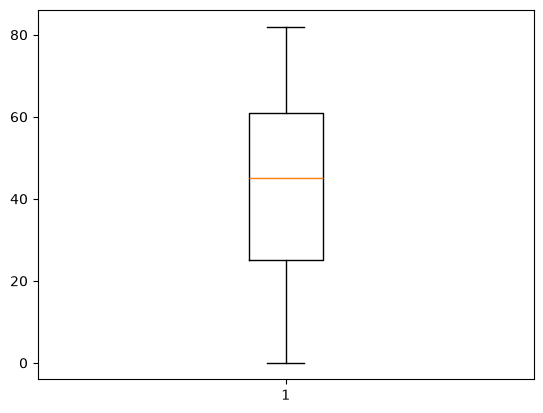

In [35]:
plt.boxplot(df['age'])
plt.show()

In [36]:
def remove_outliers_iqr(data, column_name="value"):
    Q1 = df[column_name].quantile(0.25)
    Q3 = df[column_name].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return df[(df[column_name] >= lower) & (df[column_name] <= upper)]
cleaned_df = remove_outliers_iqr(df, column_name=["age","bmi","avg_glucose_level"])

print(df.shape,cleaned_df.shape)

(5110, 17) (5110, 17)


In [37]:
df.head()

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Male,gender_Other,ever_married_Yes,Residence_type_Urban,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.6,1,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1,61.0,0,0,202.21,28.1,1,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,80.0,0,1,105.92,32.5,1,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3,49.0,0,0,171.23,34.4,1,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,79.0,1,0,174.12,24.0,1,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [38]:
X=df.drop(['stroke'],axis=1)
y=df['stroke']
display(y.head(10))

0    1
1    1
2    1
3    1
4    1
5    1
6    1
7    1
8    1
9    1
Name: stroke, dtype: int64

In [39]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,
                                   test_size= 0.20, random_state=42, stratify=y)


In [40]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()


In [41]:
X_train[['age','avg_glucose_level','bmi']] = scaler.fit_transform(
    X_train[['age','avg_glucose_level','bmi']]
)

X_test[['age','avg_glucose_level','bmi']] = scaler.transform(
    X_test[['age','avg_glucose_level','bmi']]
)

In [42]:
X_test.head()

,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Male,gender_Other,ever_married_Yes,Residence_type_Urban,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
3725,0.869552,0,0,-0.620654,0.761610,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4481,-0.015636,0,0,-0.434152,0.568373,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1545,-0.900825,0,0,0.449745,-0.024218,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
1820,-0.989344,0,0,2.250687,-0.513749,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1262,1.046590,0,0,0.155187,-0.333395,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


In [43]:
from sklearn.linear_model import LogisticRegression
 

In [44]:
model = LogisticRegression(
    
    C=1.0,
   

    max_iter=1000,
    fit_intercept=True
)

In [45]:
model.fit(X_train,y_train)


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [46]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report


In [47]:
y_pred = model.predict(X_test)

In [48]:
score=accuracy_score(y_test,y_pred)
print(score)

0.952054794520548


In [49]:
pre=precision_score(y_test,y_pred)
print(pre)

1.0


In [50]:
rec=recall_score(y_test,y_pred)
print(rec)

0.02


In [51]:
f_1=score=f1_score(y_test,y_pred)
print(f_1)

0.0392156862745098


In [52]:
calss=classification_report(y_test,y_pred)
print(calss)

              precision    recall  f1-score   support

           0       0.95      1.00      0.98       972
           1       1.00      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.98      0.51      0.51      1022
weighted avg       0.95      0.95      0.93      1022



In [53]:
!pip install xgboost


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [54]:
!pip install lightgbm


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [55]:
!pip install catboost

  Using cached catboost-1.2.10-cp314-cp314-win_amd64.whl.metadata (1.5 kB)
  Using cached graphviz-0.21-py3-none-any.whl.metadata (12 kB)
  Using cached plotly-7.1.0-py3-none-any.whl.metadata (8.8 kB)
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.8/101.7 MB 5.6 MB/s eta 0:00:19
   ---------------------------------------- 0.8/101.7 MB 5.6 MB/s eta 0:00:19
   ---------------------------------------- 0.8/101.7 MB 5.6 MB/s eta 0:00:19
    --------------------------------------- 1.3/101.7 MB 1.6 MB/s eta 0:01:03
    --------------------------------------- 1.3/101.7 MB 1.6 MB/s eta 0:01:03
    --------------------------------------- 1.8/101.7 MB 1.3 MB/s eta 0:01:16
    --------------------------------------- 2.1/101.7 MB 1.4 MB/s eta 0:01:11
    --------------------------------------- 2.4/101.7 MB 1.4 MB/s eta 0:01:12
   - ----------------------------


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: Exception:
Traceback (most recent call last):
  File "C:\Users\abdoa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pip\_vendor\urllib3\response.py", line 897, in _error_catcher
    yield
  File "C:\Users\abdoa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pip\_vendor\urllib3\response.py", line 1022, in _raw_read
    data = self._fp_read(amt, read1=read1) if not fp_closed else b""
           ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^
  File "C:\Users\abdoa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pip\_vendor\urllib3\response.py", line 1005, in _fp_read
    return self._fp.read(amt) if amt is not None else self._fp.read()
           ~~~~~~~~~~~~~^^^^^
  File "C:\Users\abdoa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pip\_vendor\cachecontrol\filewrapper.py", line 100, in read
    data: bytes = self.__fp.read(amt)

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
#from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


In [58]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    #"XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    #"CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    #"LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/10 [00:00<?, ?it/s]


Confusion Matrix:
 [[972   0]
 [ 49   1]]


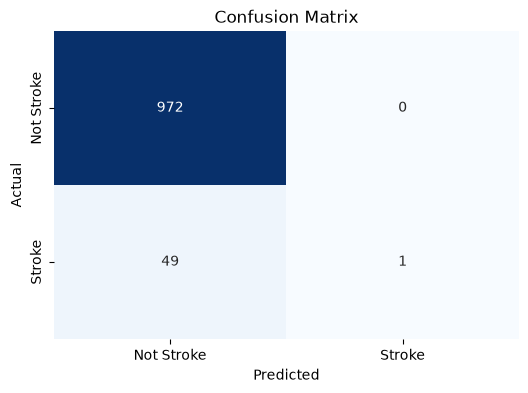


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.98       972
      Stroke       1.00      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.98      0.51      0.51      1022
weighted avg       0.95      0.95      0.93      1022

ROC-AUC: 0.8419547325102881


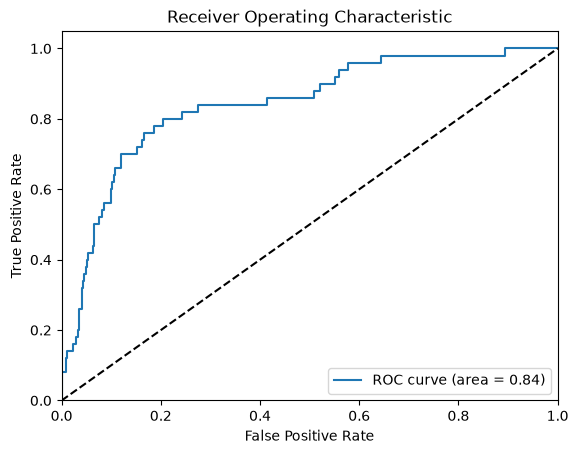

PR AUC: 0.2696583873174889


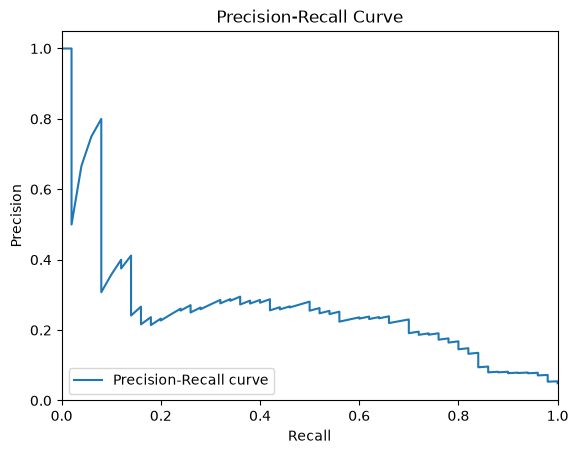

c:\Users\abdoa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
 10%|█         | 1/10 [00:00<00:03,  2.78it/s]


Confusion Matrix:
 [[964   8]
 [ 50   0]]


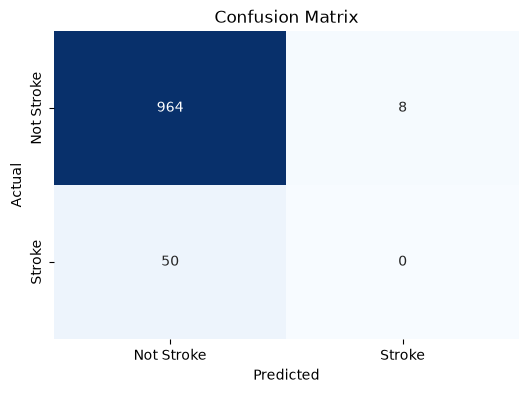


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97       972
      Stroke       0.00      0.00      0.00        50

    accuracy                           0.94      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.94      0.92      1022

ROC-AUC: 0.6023045267489712


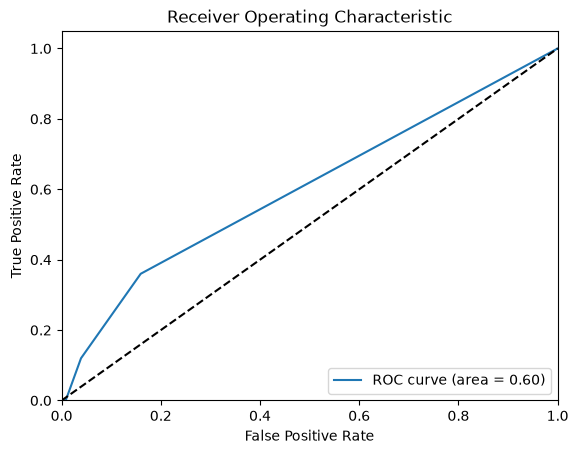

PR AUC: 0.07264588922835814


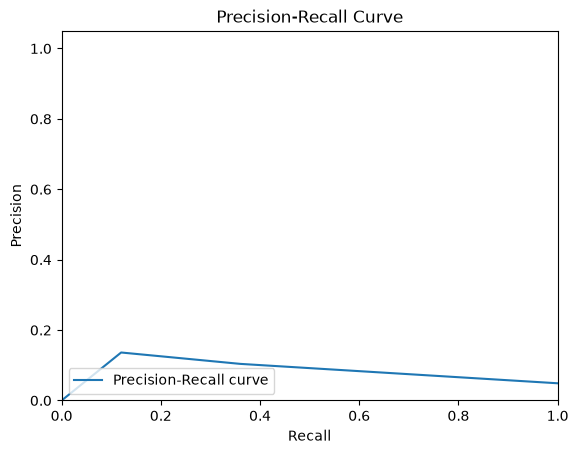

 20%|██        | 2/10 [00:00<00:03,  2.19it/s]c:\Users\abdoa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



Confusion Matrix:
 [[972   0]
 [ 50   0]]


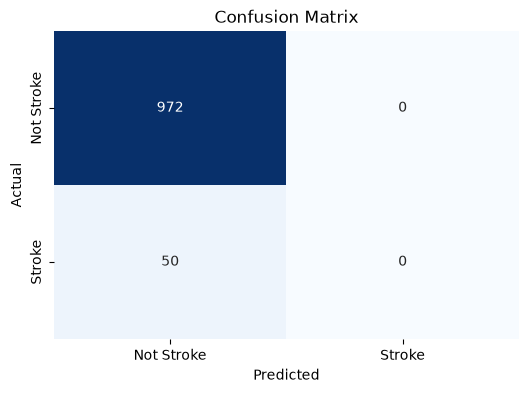


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       972
      Stroke       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022

ROC-AUC: 0.6869135802469135


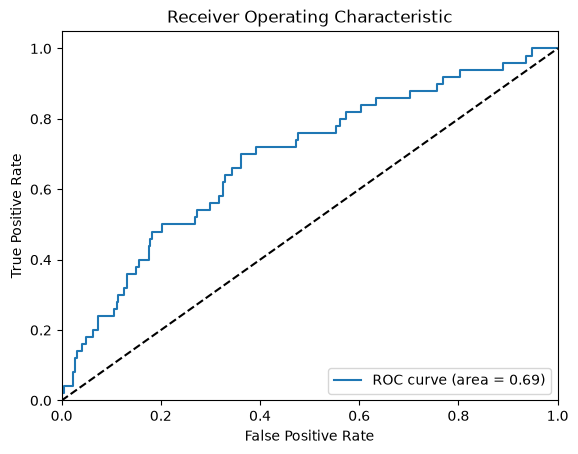

PR AUC: 0.113964943851636


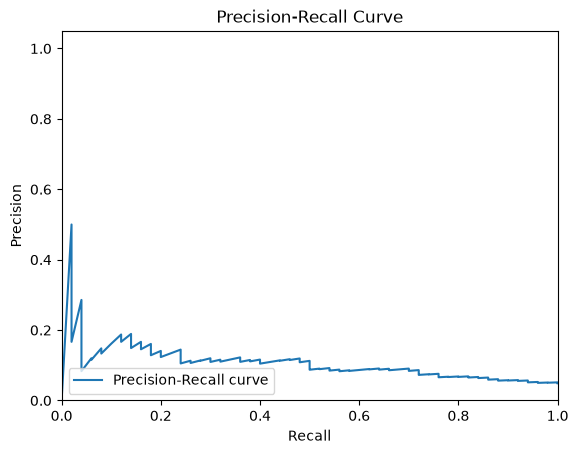

c:\Users\abdoa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\abdoa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
 30%|███       | 3/10 [00:02<00:06,  1.14it/s]


Confusion Matrix:
 [[922  50]
 [ 43   7]]


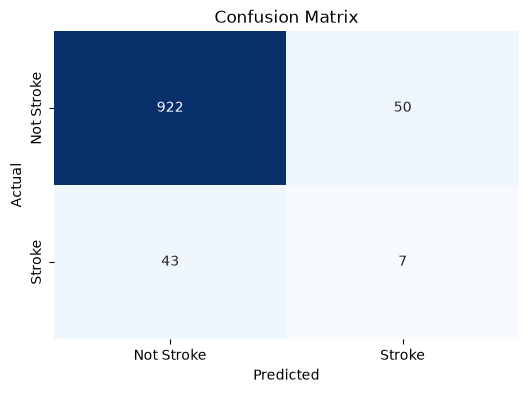


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.96      0.95      0.95       972
      Stroke       0.12      0.14      0.13        50

    accuracy                           0.91      1022
   macro avg       0.54      0.54      0.54      1022
weighted avg       0.91      0.91      0.91      1022

ROC-AUC: 0.5442798353909466


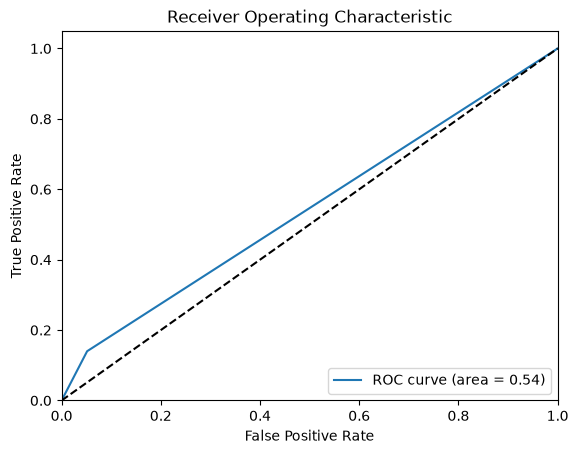

PR AUC: 0.05926734644831256


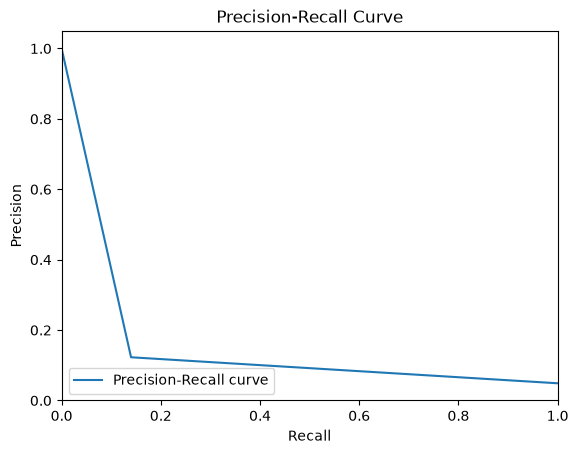

 40%|████      | 4/10 [00:02<00:03,  1.53it/s]


Confusion Matrix:
 [[186 786]
 [  1  49]]


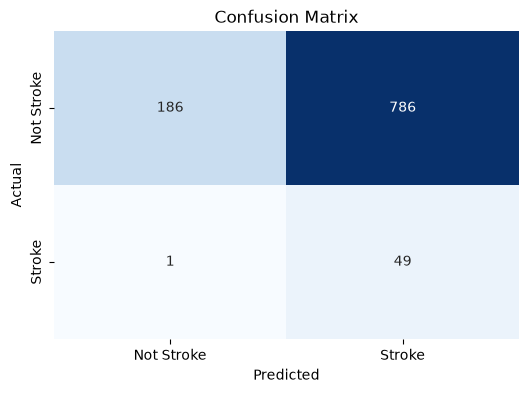


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.99      0.19      0.32       972
      Stroke       0.06      0.98      0.11        50

    accuracy                           0.23      1022
   macro avg       0.53      0.59      0.22      1022
weighted avg       0.95      0.23      0.31      1022

ROC-AUC: 0.7991152263374485


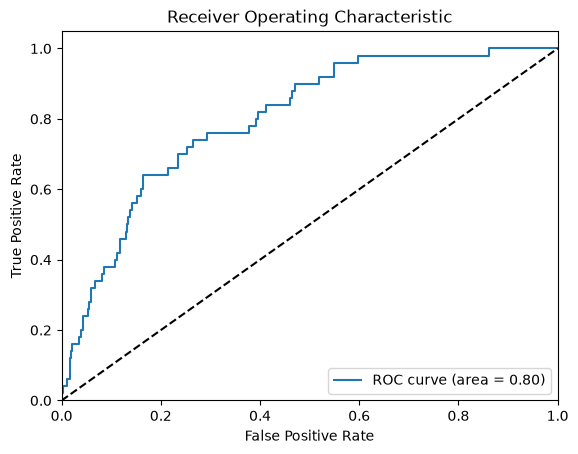

PR AUC: 0.1729666551399662


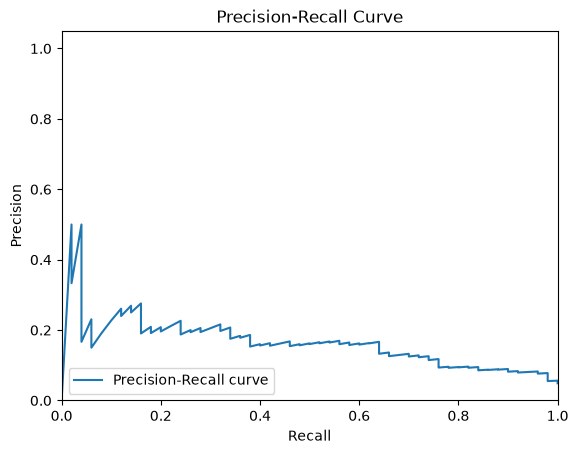

 50%|█████     | 5/10 [00:02<00:02,  1.88it/s]


Confusion Matrix:
 [[970   2]
 [ 49   1]]


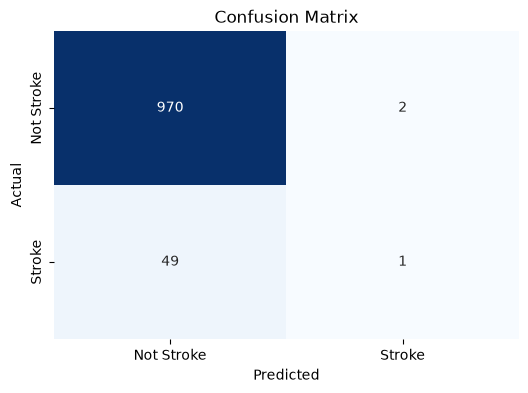


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       972
      Stroke       0.33      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.64      0.51      0.51      1022
weighted avg       0.92      0.95      0.93      1022

ROC-AUC: 0.7908024691358024


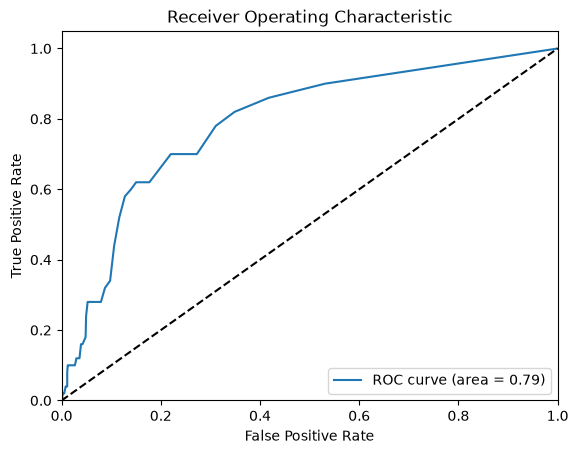

PR AUC: 0.15871686474545021


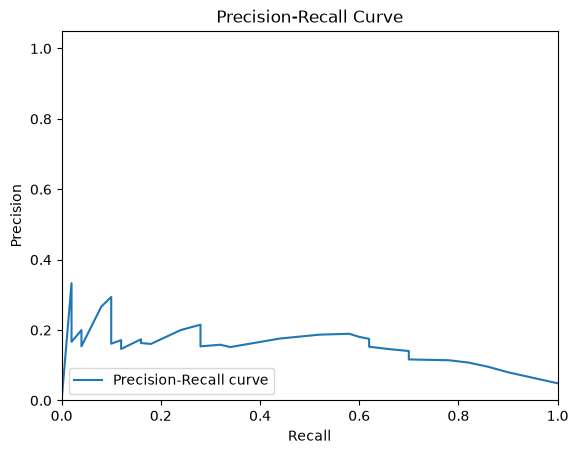

 60%|██████    | 6/10 [00:03<00:02,  1.71it/s]


Confusion Matrix:
 [[961  11]
 [ 47   3]]


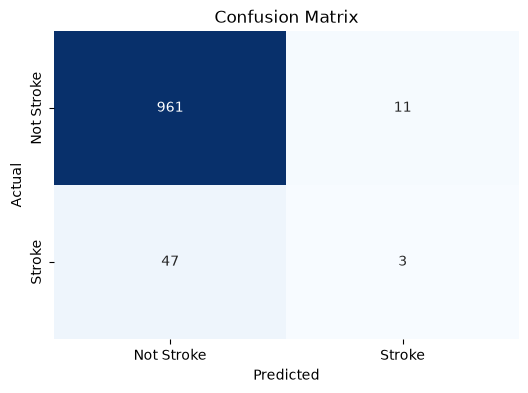


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97       972
      Stroke       0.21      0.06      0.09        50

    accuracy                           0.94      1022
   macro avg       0.58      0.52      0.53      1022
weighted avg       0.92      0.94      0.93      1022

ROC-AUC: 0.7524588477366254


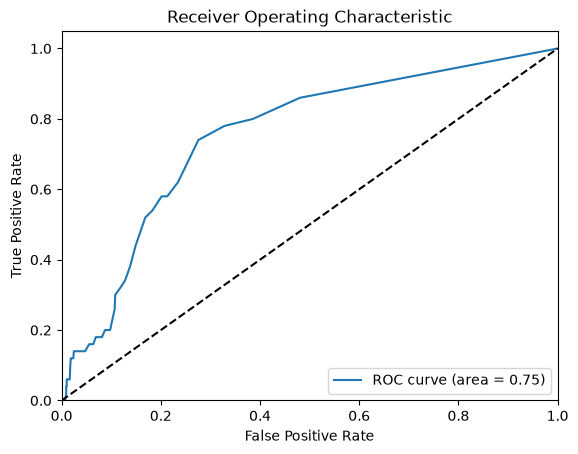

PR AUC: 0.1215808733965531


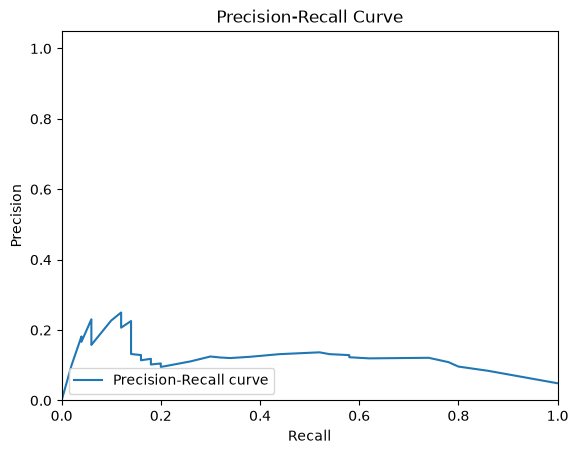

 70%|███████   | 7/10 [00:04<00:01,  1.63it/s]


Confusion Matrix:
 [[972   0]
 [ 50   0]]


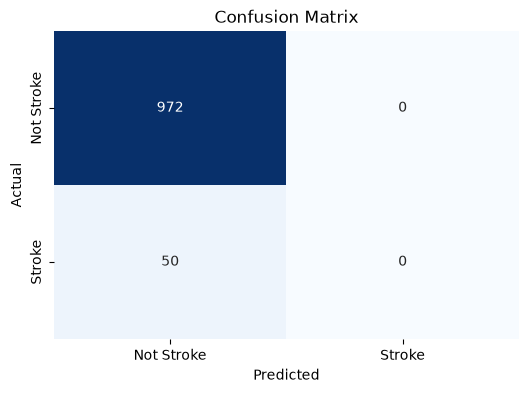


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       972
      Stroke       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022

ROC-AUC: 0.8287448559670783


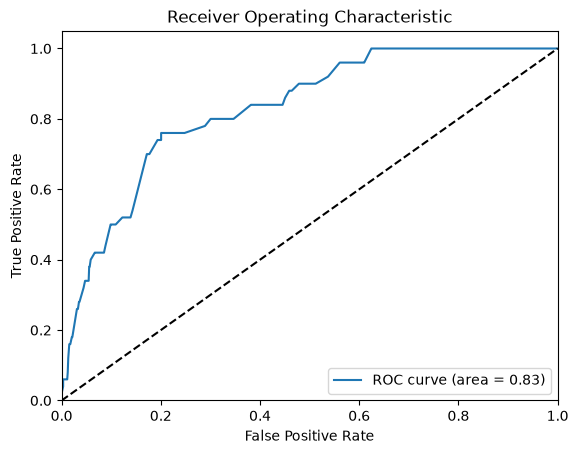

PR AUC: 0.22525228523943236


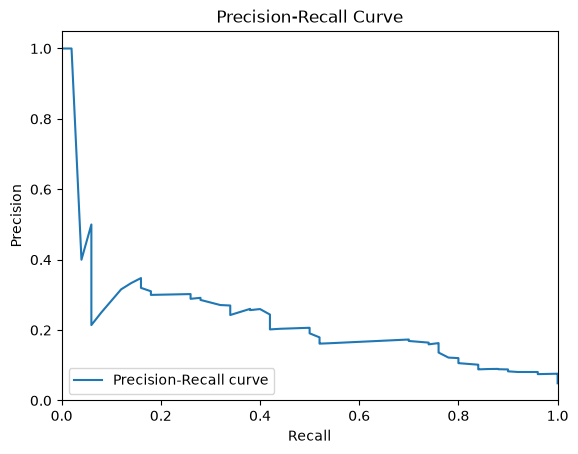

c:\Users\abdoa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\abdoa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
 80%|████████  | 8/10 [00:04<00:01,  1.74it/s]


Confusion Matrix:
 [[969   3]
 [ 50   0]]


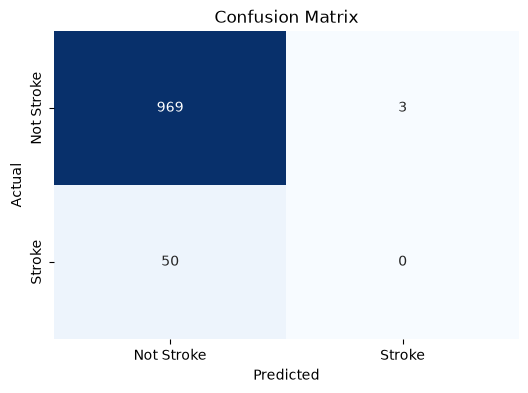


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       972
      Stroke       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022

ROC-AUC: 0.8294958847736625


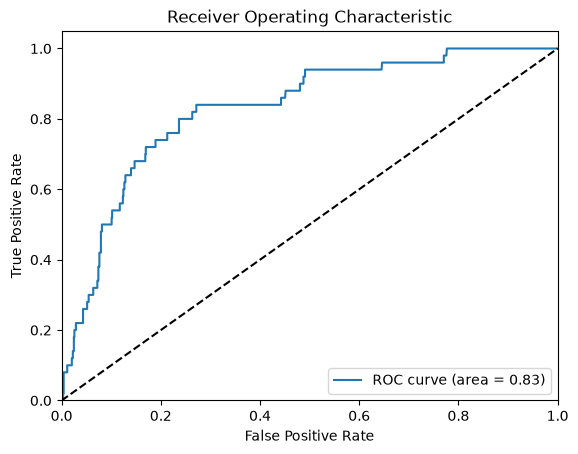

PR AUC: 0.20307567085607559


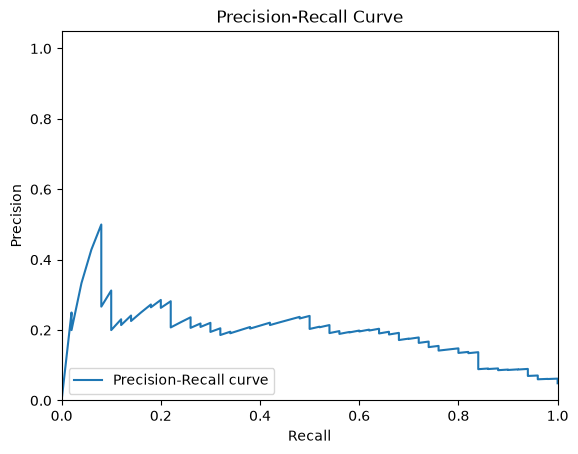

 90%|█████████ | 9/10 [00:05<00:00,  1.56it/s]


Confusion Matrix:
 [[963   9]
 [ 47   3]]


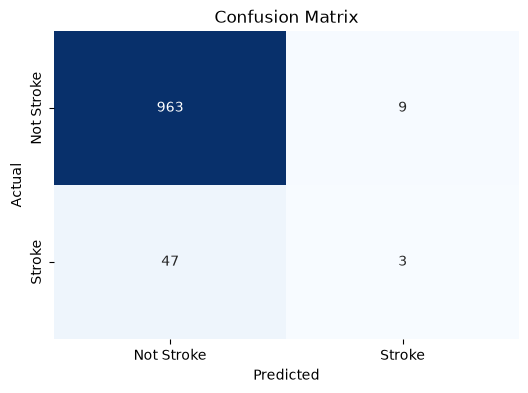


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97       972
      Stroke       0.25      0.06      0.10        50

    accuracy                           0.95      1022
   macro avg       0.60      0.53      0.53      1022
weighted avg       0.92      0.95      0.93      1022

ROC-AUC: 0.8247325102880658


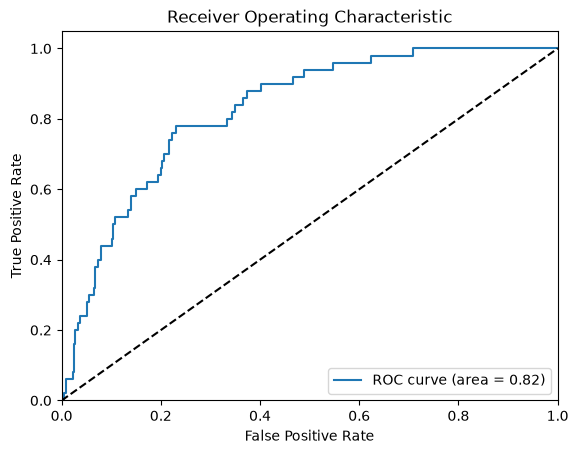

PR AUC: 0.1738485226065868


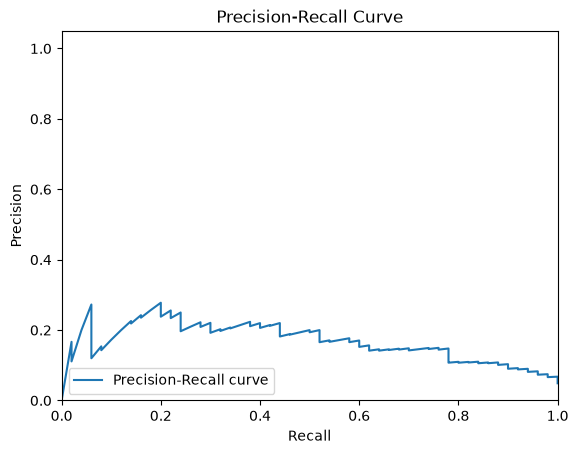

100%|██████████| 10/10 [00:06<00:00,  1.65it/s]


In [59]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)
    
    

    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Stroke','Stroke']
                ,yticklabels=['Not Stroke','Stroke'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--') 
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }
    


Confusion Matrix:
 [[944  28]
 [ 40  10]]


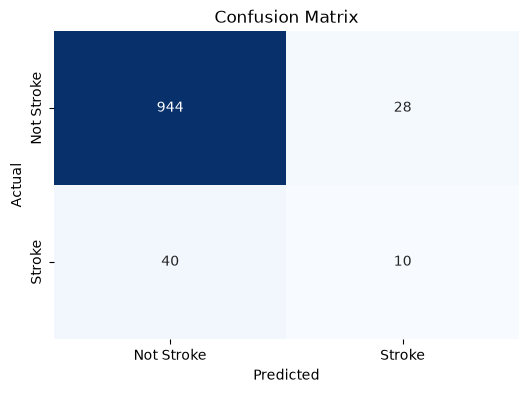


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.96      0.97      0.97       972
      Stroke       0.26      0.20      0.23        50

    accuracy                           0.93      1022
   macro avg       0.61      0.59      0.60      1022
weighted avg       0.93      0.93      0.93      1022

ROC-AUC: 0.8288683127572016


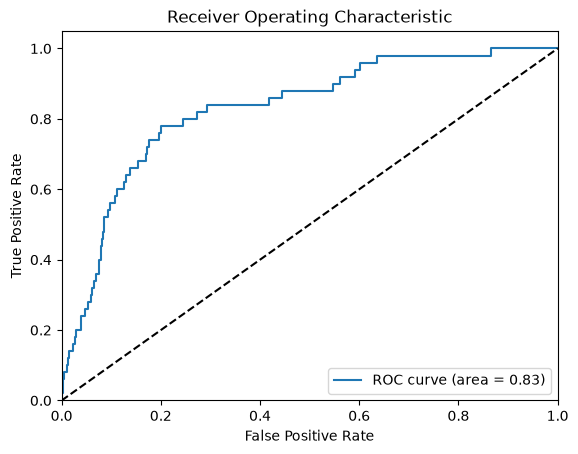

PR AUC: 0.21669137337339744


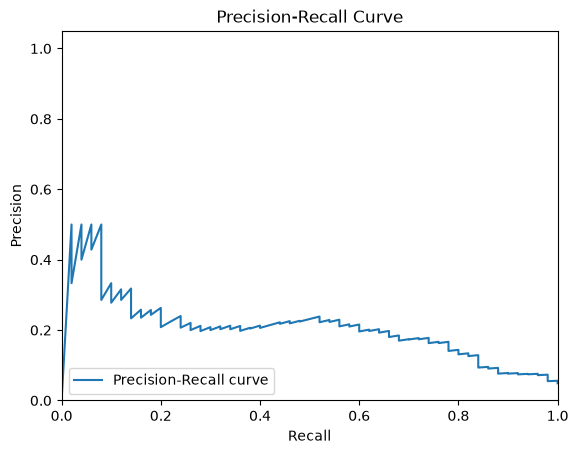

In [60]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        #("xgb", models["XGBoost"]),
    ],
    voting="soft" # voting='hard' / voting='soft', weights=[2, 1, 2,1]
)

voting_model.fit(X_train, y_train)
voting_train_pred = voting_model.predict(X_train)
voting_test_pred = voting_model.predict(X_test)


cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, voting_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = voting_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--') 
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred),
    "Test Precision": precision_score(y_test, voting_test_pred),
    "Train Recall": recall_score(y_train, voting_train_pred),
    "Test Recall": recall_score(y_test, voting_test_pred),
    "Train F1 Score": f1_score(y_train, voting_train_pred),
    "Test F1 Score": f1_score(y_test, voting_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}


Confusion Matrix:
 [[970   2]
 [ 49   1]]


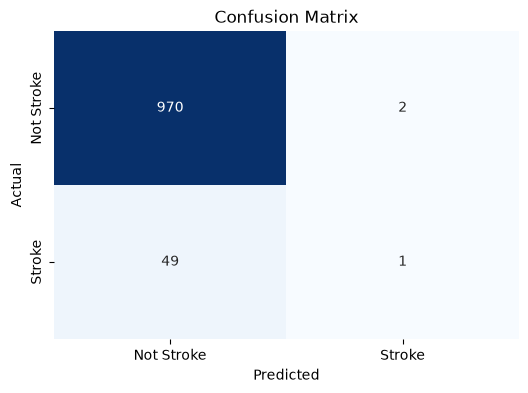


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       972
      Stroke       0.33      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.64      0.51      0.51      1022
weighted avg       0.92      0.95      0.93      1022

ROC-AUC: 0.8308847736625515


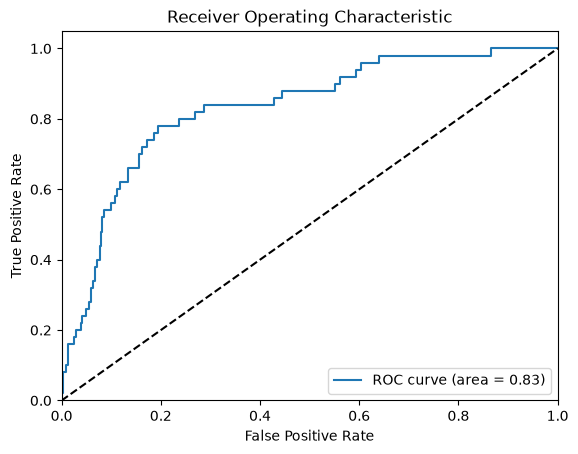

PR AUC: 0.2345991415074756


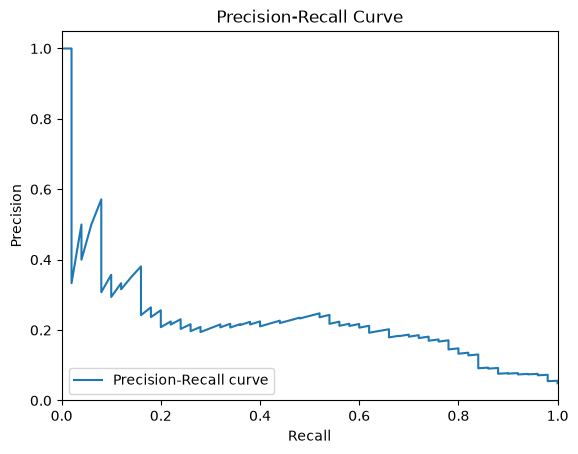

In [61]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        #("lgbm", models["LightGBM"]),

        
    ],
    #final_estimator=XGBClassifier(max_iter=2000),
    stack_method="predict_proba",   # best for classification usually
    n_jobs=-1
)

# Train
stack_auto.fit(X_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(X_train)
stack_auto_test_pred  = stack_auto.predict(X_test)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, stack_auto_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = stack_auto.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--') 
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier "] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred),
    "Test Precision": precision_score(y_test, stack_auto_test_pred),
    "Train Recall": recall_score(y_train, stack_auto_train_pred),
    "Test Recall": recall_score(y_test, stack_auto_test_pred),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [62]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)

In [63]:
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
Voting Classifier,0.998532,0.933464,0.975369,0.263158,0.994975,0.20,0.985075,0.227273,0.996845,0.585597,0.828868,0.216691
Decision Tree,1.000000,0.909002,1.000000,0.122807,1.000000,0.14,1.000000,0.130841,1.000000,0.544280,0.544280,0.059267
Naive Bayes,0.219667,0.229941,0.058459,0.058683,0.994975,0.98,0.110429,0.110734,0.587485,0.585679,0.799115,0.172967
Hist Gradient Boosting,0.994129,0.945205,1.000000,0.250000,0.879397,0.06,0.935829,0.096774,0.939698,0.525370,0.824733,0.173849
Extra Trees,1.000000,0.943249,1.000000,0.214286,1.000000,0.06,1.000000,0.093750,1.000000,0.524342,0.752459,0.121581
Logistic Regression,0.951321,0.952055,0.000000,1.000000,0.000000,0.02,0.000000,0.039216,0.500000,0.510000,0.841955,0.269658
Stacking Classifier,0.960127,0.950098,1.000000,0.333333,0.180905,0.02,0.306383,0.037736,0.590452,0.508971,0.830885,0.234599
Random Forest,1.000000,0.950098,1.000000,0.333333,1.000000,0.02,1.000000,0.037736,1.000000,0.508971,0.790802,0.158717
SVC,0.951321,0.951076,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.500000,0.500000,0.686914,0.113965
KNN,0.952055,0.943249,0.636364,0.000000,0.035176,0.00,0.066667,0.000000,0.517074,0.495885,0.602305,0.072646


<Axes: >

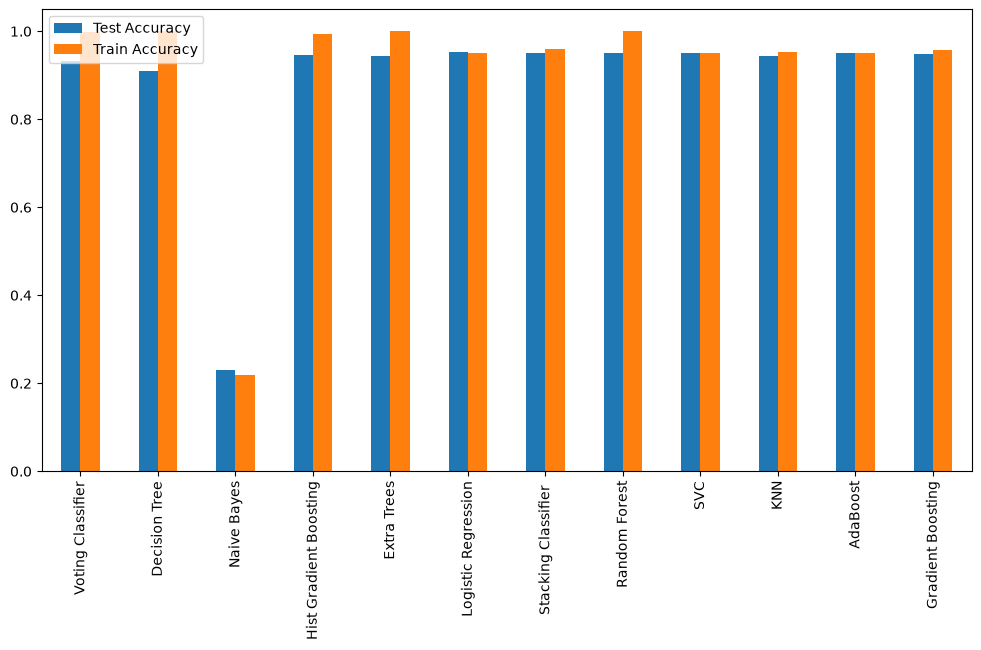

In [64]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

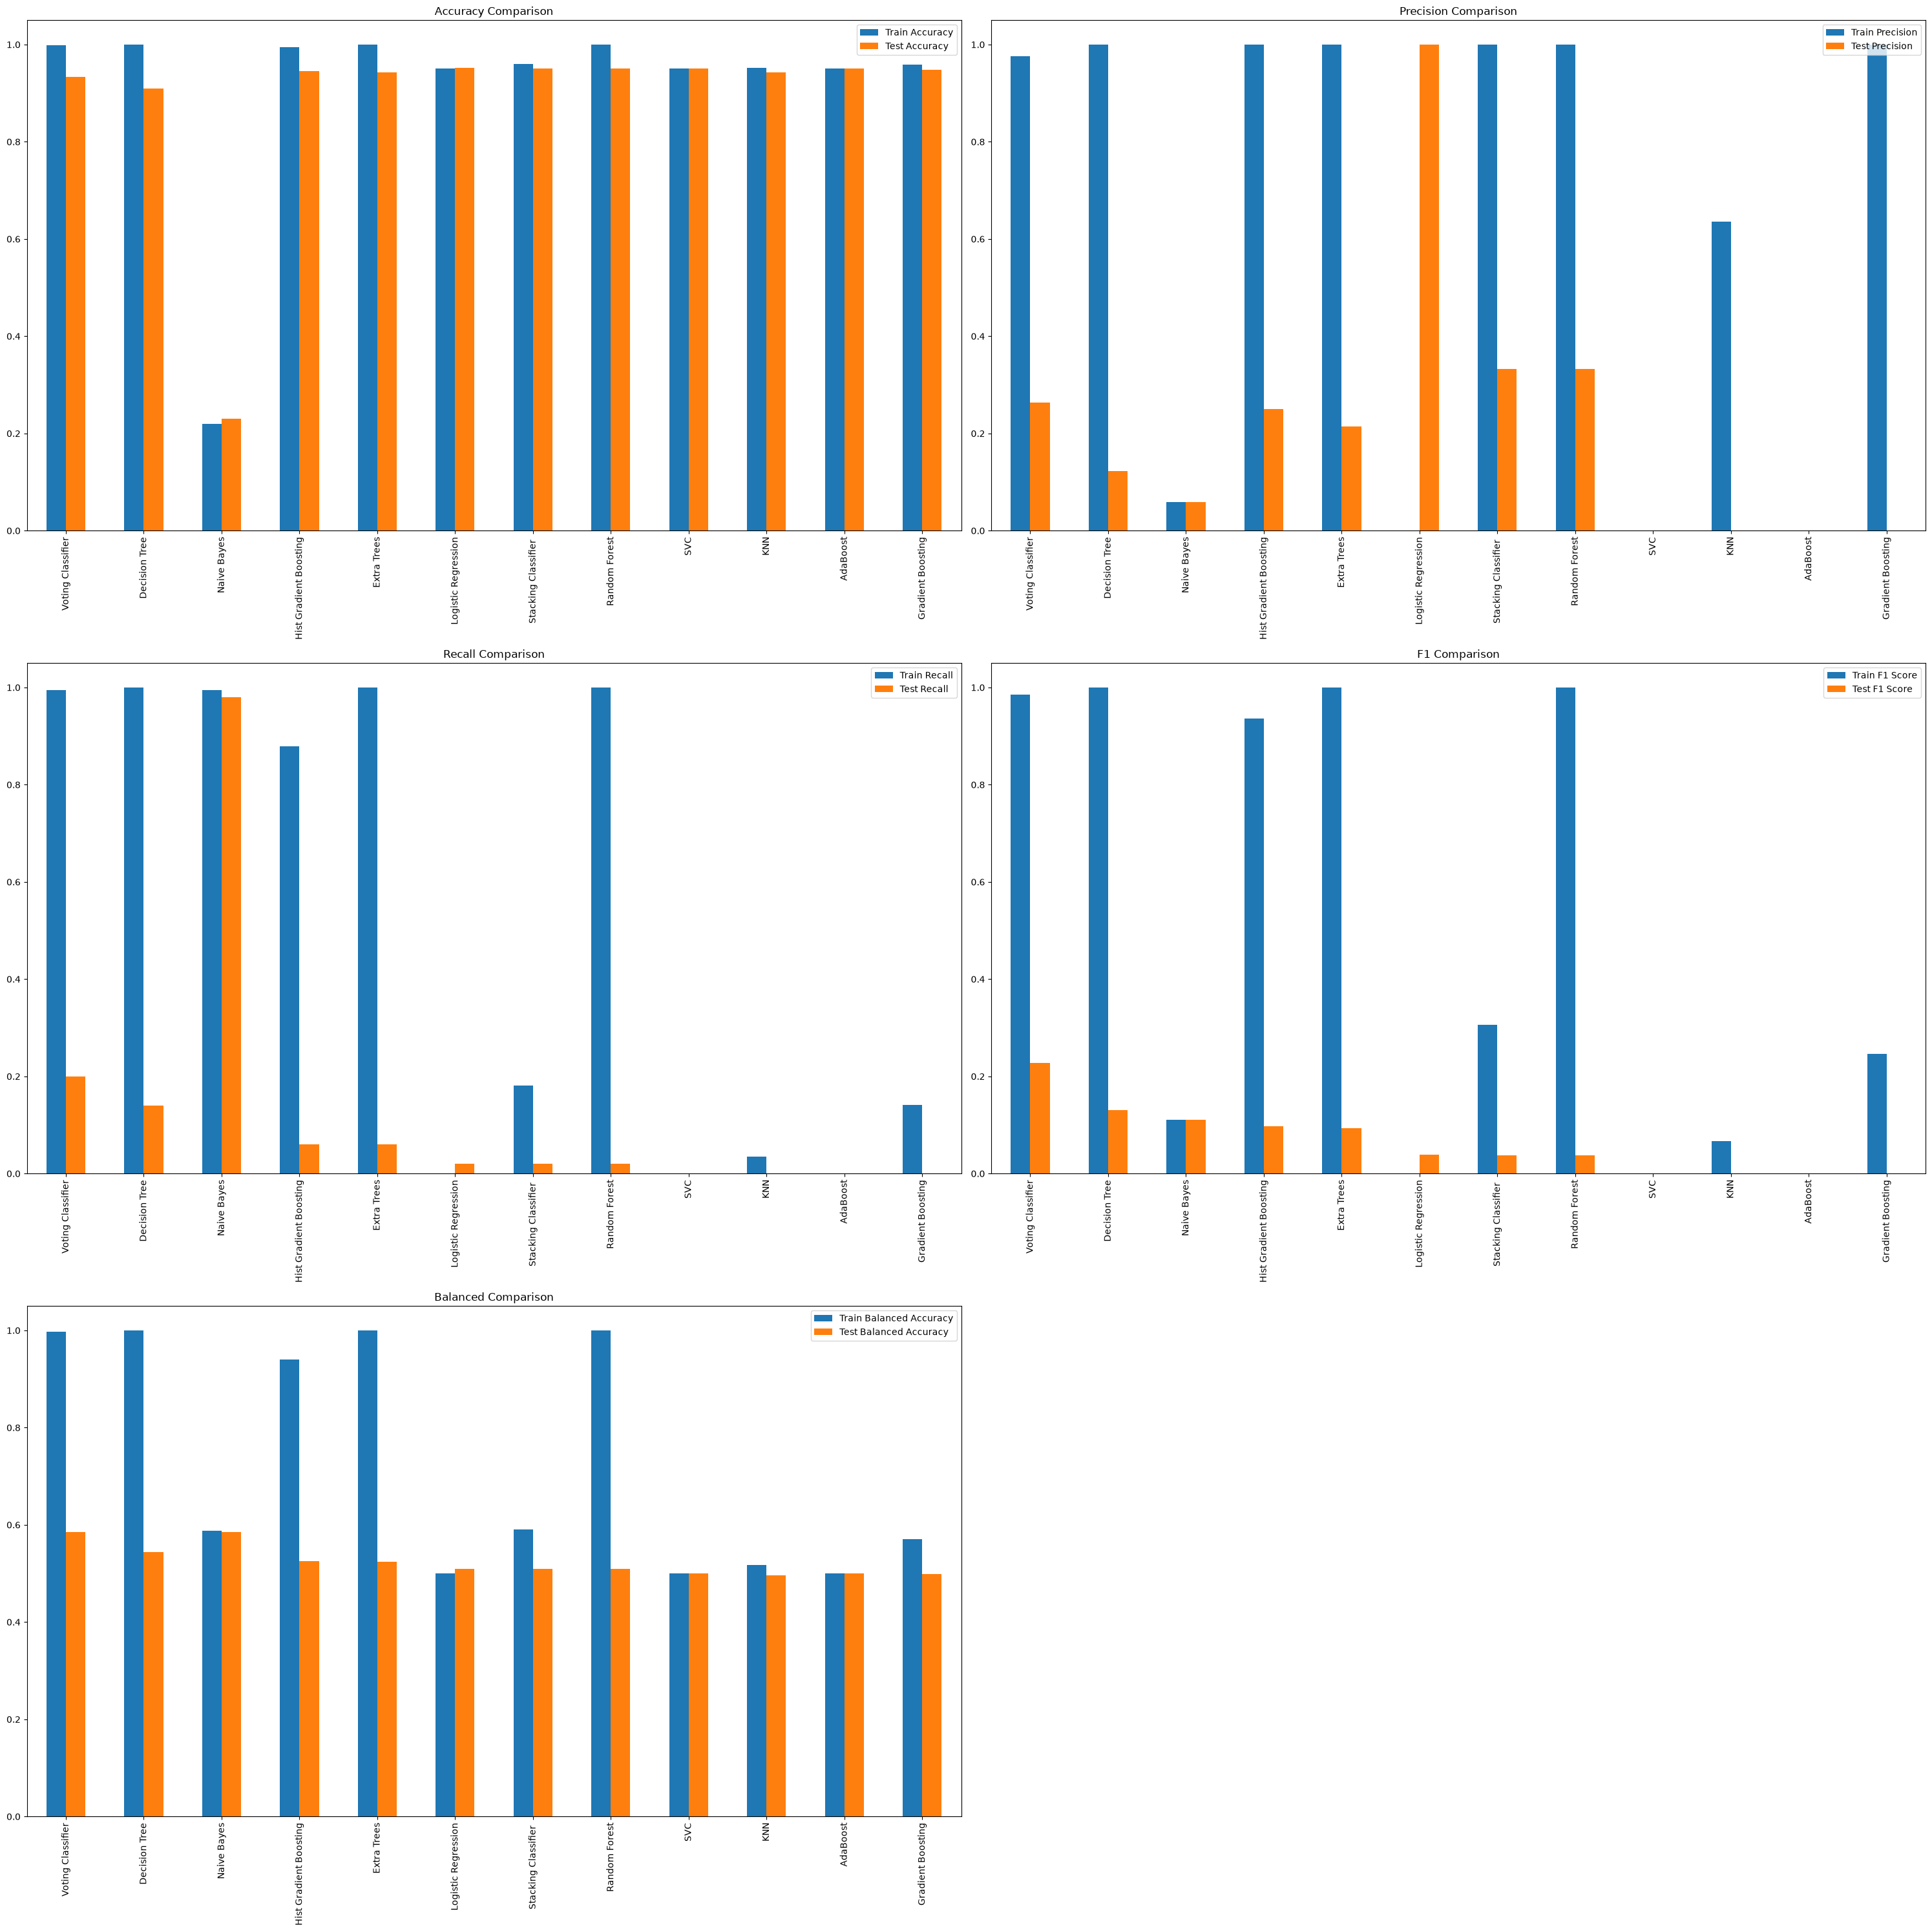

In [65]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)   
    results_df[col].plot.bar(ax=ax)   
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()

In [66]:
from sklearn.decomposition import PCA

In [67]:
model_PCA=PCA(n_components=7,random_state=42)

In [68]:
X_train_PCA = model_PCA.fit_transform(X_train)
X_test_PCA = model_PCA.transform(X_test)

In [69]:
X_train_PCA.shape

(4088, 7)

In [70]:
X_train_PCA = pd.DataFrame(
    X_train_PCA,
    columns=[f'PC{i+1}' for i in range(X_train_PCA.shape[1])]
)

In [72]:
# PCA feature contribution to PC1 (simplified)
feature_names = df.columns
loadings = model_PCA.components_.T

# Get absolute contribution to PC1
contrib_pc1 = np.abs(loadings[:, 0])

# Get top k features
k = 5
top_idx = np.argsort(contrib_pc1)[-k:][::-1]

top_features = feature_names[top_idx]
top_values = contrib_pc1[top_idx]

# Print results
print("Top features contributing to PC1:")
for f, v in zip(top_features, top_values):
    print(f"{f}: {v:.4f}")


Top features contributing to PC1:
age: 0.6413
bmi: 0.5490
avg_glucose_level: 0.4116
gender_Other: 0.2458
work_type_Self-employed: 0.1778
